# 02 · MM serbest enerjisi: alkimik FEP + MBAR
*Makale: Bölüm 2.1, Denklem 3–5; Şekil 2 kırmızı üst kutu.*

Misafirin çevresiyle etkileşimini bir $\lambda$ parametresiyle adım adım "kapatıyoruz":

$$H_\lambda = H_\text{çevre} + H_\text{misafir} + \lambda\,H_\text{etkileşim}\qquad(\text{makale Denklem 4})$$

Önce elektrostatik etkileşimi ($\lambda_e$: 1→0), sonra van der Waals etkileşimini ($\lambda_s$: 1→0)
kapatıyoruz. vdW kapatılırken, atomlar üst üste binince enerjinin sonsuza gitmemesi için "soft-core"
potansiyel kullanılıyor. Her $\lambda$ durumunda MD yapıyoruz ve **her örnekte tüm durumların enerjisini**
kaydediyoruz. Sonra makaledeki gibi **MBAR** ile durumlar arası serbest enerji farklarını hesaplıyoruz.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import fep, mmsys
states = fep.lambda_schedule()
print(f"{len(states)} λ durumu (λ_elektrostatik, λ_sterik):")
print(states)
p = config.P()
print(f"Her durumda {p['fep_equil_ps']} ps dengeleme + {p['fep_prod_ps']} ps üretim, "
      f"{p['fep_sample_ps']} ps'de bir örnek")

13 λ durumu (λ_elektrostatik, λ_sterik):
[(1.0, 1.0), (0.75, 1.0), (0.5, 1.0), (0.25, 1.0), (0.0, 1.0), (0.0, 0.85), (0.0, 0.7), (0.0, 0.55), (0.0, 0.42), (0.0, 0.3), (0.0, 0.2), (0.0, 0.1), (0.0, 0.0)]
Her durumda 4 ps dengeleme + 12 ps üretim, 0.4 ps'de bir örnek


In [3]:
raw = {}
for leg in ["complex", "solvent"]:
    with store.timed(f"02_fep_{leg}") as rec:
        raw[leg] = fep.run_leg(leg)
        rec["simulated_ps"] = len(states) * (p["fep_equil_ps"] + p["fep_prod_ps"])
    store.save_npz(f"fep_{leg}.npz", **raw[leg])

OpenMM platformu: CPU  (mevcut: ['Reference', 'CPU'])


  [complex] durum  1/13  λ_e=1.00 λ_s=1.00   geçen süre     56 s


  [complex] durum  2/13  λ_e=0.75 λ_s=1.00   geçen süre    105 s


  [complex] durum  3/13  λ_e=0.50 λ_s=1.00   geçen süre    153 s


  [complex] durum  4/13  λ_e=0.25 λ_s=1.00   geçen süre    201 s


...

  [solvent] durum  9/13  λ_e=0.00 λ_s=0.42   geçen süre    427 s


  [solvent] durum 10/13  λ_e=0.00 λ_s=0.30   geçen süre    475 s


  [solvent] durum 11/13  λ_e=0.00 λ_s=0.20   geçen süre    522 s


  [solvent] durum 12/13  λ_e=0.00 λ_s=0.10   geçen süre    569 s


  [solvent] durum 13/13  λ_e=0.00 λ_s=0.00   geçen süre    615 s
[süre] 02_fep_solvent: 616.1 s


In [4]:
an = {leg: fep.mbar_analysis(raw[leg]["u_kln"]) for leg in raw}
res = fep.combine(an["complex"], an["solvent"])
expG, expE = config.exp_dG_kj()
print(f"ΔG_c (kompleksde kapatma) = {res['dG_complex_decouple']:7.2f} kJ/mol")
print(f"ΔG_s (suda kapatma)       = {res['dG_solvent_decouple']:7.2f} kJ/mol")
print(f"Standart durum düzeltmesi = {res['standard_state_corr']:7.2f} kJ/mol  (V_site={res['v_site_nm3']:.3f} nm³)")
print(f"------------------------------------------")
print(f"ΔG_bağlanma (MM)          = {res['dG_bind']:7.2f} ± {res['dG_bind_err']:.2f} kJ/mol")
print(f"Deney                     = {expG:7.2f} ± {expE:.2f} kJ/mol")
store.save_json("results.json", {"dG_MM": res})

ΔG_c (kompleksde kapatma) =  141.42 kJ/mol
ΔG_s (suda kapatma)       =  104.58 kJ/mol
Standart durum düzeltmesi =    4.88 kJ/mol  (V_site=0.232 nm³)
------------------------------------------
ΔG_bağlanma (MM)          =  -31.95 ± 4.72 kJ/mol
Deney                     =  -12.76 ± 0.04 kJ/mol


PosixPath('/home/claude/qb/results/test/results.json')

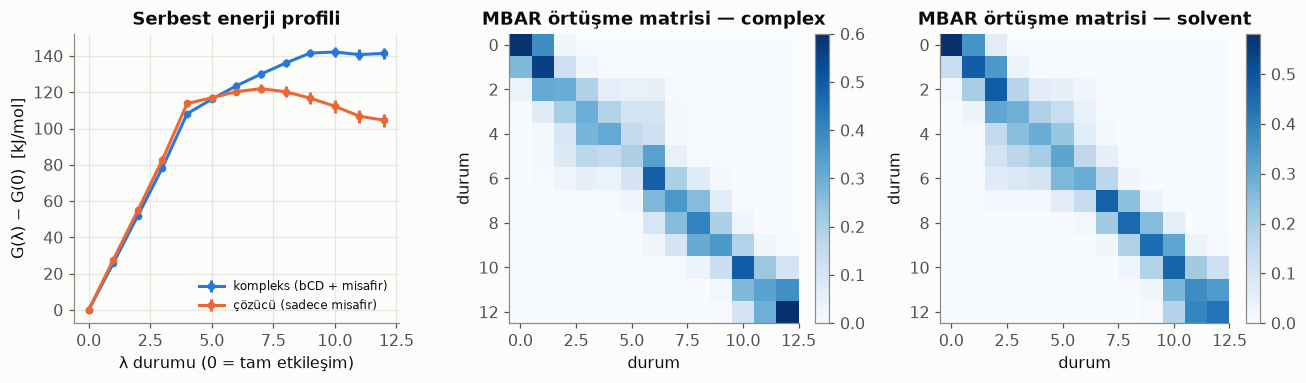

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for leg in ["complex", "solvent"]:
    f = an[leg]["f_kJ"]; df = an[leg]["df_kJ"]
    axs[0].errorbar(range(len(f)), f, yerr=df, color=LEG[leg], marker="o", ms=4, label=LEG_TR[leg])
axs[0].set_xlabel("λ durumu (0 = tam etkileşim)"); axs[0].set_ylabel("G(λ) − G(0)  [kJ/mol]")
axs[0].set_title("Serbest enerji profili"); axs[0].legend(fontsize=8)
for ax, leg in zip(axs[1:], ["complex", "solvent"]):
    O = an[leg]["overlap"]
    if O is not None:
        im = ax.imshow(O, cmap="Blues", vmin=0, vmax=max(0.3, O.max()))
        ax.set_title(f"MBAR örtüşme matrisi — {leg}"); ax.set_xlabel("durum"); ax.set_ylabel("durum")
        ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

**Nasıl okunur?**
- **Örtüşme matrisi:** Komşu λ durumları arasındaki örtüşme (köşegenin hemen yanındaki değerler)
  ~0.03'ten büyük olmalı. Değilse o aralığa yeni bir λ durumu eklenmeli. Makale de adımları bu ölçüte göre seçiyor.
- **MM sonucu ile deney arasındaki fark:** Bu fark kuvvet alanının hatası + örnekleme hatasından oluşuyor.
  Makaledeki fikir, kuvvet alanı hatasını kuantum mekaniğiyle (QM) düzeltmek.

### Kuantum hesapları için anlık görüntü havuzu
Tam etkileşimli (λ=1) durumdan yapılar topluyoruz. 03–05. notebook'larda QM/MM ve ML adımları
bu yapılar üzerinde çalışacak (makalede ~2000 anlık görüntü).

In [6]:
for leg in ["complex", "solvent"]:
    with store.timed(f"02_havuz_{leg}") as rec:
        X, B = fep.sample_endstate_pool(leg)
        rec["frames"] = len(X)
    store.save_npz(f"pool_{leg}.npz", X=X, B=B)
    print(leg, X.shape)

  [complex] 120 anlık görüntü, 160 s
[süre] 02_havuz_complex: 193.4 s


complex (120, 4669, 3)


  [solvent] 120 anlık görüntü, 142 s
[süre] 02_havuz_solvent: 172.8 s


solvent (120, 4522, 3)
